# Daytime Radiative Cooling - Data-driven Model of $Q_{net}$

**Sample 2 campaign (17/04/2026 - ongoing), INRiM rooftop, Turin.**

This notebook builds the data-driven model that Slide 11 of the supervisor's UIT 2026 talk
(*An Ambient Temperature-tracking Setup for Outdoor Characterization of Passive Radiative Cooling
Materials*, Bertiglia, **Forte**, Lopardo, Girard, Pattelli & Fasano) names as the objective for
this sample:

> *"Sample 2: build a **data-driven model** and find correlations between $Q_{net}$ and atmospheric
> variables, **especially $T_{sky}$**."*

His Slide 13 already reports that model for **Sample 1** (4/09 - 5/10/2025), with the footnote
*"the database from Sample 1 was used, as Sample 2 experimental campaign is still in progress."*
This notebook is the missing Sample 2 half of that comparison, and it follows his published
algorithm step for step so the two are directly comparable.

### His algorithm (Slide 13) and where each step lives here

| # | Slide 13 step | Section below |
|---|---|---|
| 1 | Raw data acquisition (RAFT, weather station, IR sky sensor) | 1 |
| 2 | Raw data pre-processing: **remove NaNs**, synchronise on a **5-min grid** | 2 |
| 3 | Feature matrix $[T_{amb}, RH, G, v, T_{sky}] \rightarrow Q_{net}$ | 4 |
| 4 | Data pre-processing: **min-max normalisation** | 5 |
| 5 | **K-fold partitioning (k = 5)**: 4 folds train, 1 fold validation | 5 |
| 6 | MLP training and validation, hyperparameter tuning | 7 |
| 7 | Metrics evaluation: **lowest RMSE** | 7 |
| 8 | Best configuration selection and final MLP training | 8 |
| 9 | Metrics evaluation: **RMSE, $R^2$** | 8 |

**His Sample 1 benchmark: RMSE = 9.5 W m$^{-2}$, $R^2$ = 0.92**, with hyperparameters
`[20 10]`, logistic sigmoid transfer function, Bayesian-regularised training.
His multi-linear regression baseline on the same data reached only $R^2$ = 0.21.

### Three deliberate departures, each justified in place

1. **The sign of $Q_{net}$ is flipped** relative to `model_input_5min.csv` - Section 3.
2. **Interpolated rows are excluded from the primary model** - Section 2.
3. **The 10-min moving average is treated as a variant, not as the primary pipeline** - Section 2.

All figures are produced inline in this notebook. Nothing is written to a figures folder.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_val_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# The MLP does not always drive lbfgs to its tolerance inside max_iter. That is expected for a
# small network on ~15k samples and does not invalidate the fit, so the notice is silenced here
# and convergence is reported explicitly in Section 8 instead.
warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
MERGED_PATH = PROJECT_ROOT / "processed" / "merged_dataset_104957.csv"
OUT_PATH = PROJECT_ROOT / "processed" / "model_input_final.csv"

FEATURES = ["T_amb", "RH", "v", "G", "T_sky"]
TARGET = "Q_net"
MODEL_COLS = ["timestamp"] + FEATURES + [TARGET]

GRID = "5min"     # Slide 13: "Synchronize data (5 min. grid)"
SMOOTH = "10min"  # from the Teams call only - NOT part of the Slide 13 algorithm
K_FOLDS = 5       # Slide 13: "K-fold partitioning (k=5)"
SEED = 42

LABELS = {
    "T_amb": ("Ambient temperature", r"$T_{amb}$ [$^\circ$C]", "#1f77b4"),
    "RH":    ("Relative humidity",   r"RH [%]",                 "#2ca02c"),
    "v":     ("Wind speed",          r"$v$ [m s$^{-1}$]",       "#9467bd"),
    "G":     ("Solar irradiance",    r"$G$ [W m$^{-2}$]",       "#ff7f0e"),
    "T_sky": ("Sky temperature",     r"$T_{sky}$ [$^\circ$C]",  "#d62728"),
    "Q_net": ("Net heat flux",       r"$Q_{net}$ [W m$^{-2}$]", "#111111"),
}

# The supervisor's Sample 1 result, for side-by-side comparison throughout.
REF_RMSE, REF_R2, REF_LINEAR_R2 = 9.5, 0.92, 0.21

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "font.size": 11, "axes.titlesize": 13, "figure.autolayout": False,
})

print(f"pandas {pd.__version__} | numpy {np.__version__}")
import sklearn; print(f"scikit-learn {sklearn.__version__}")
print(f"source: {MERGED_PATH.name}")

pandas 3.0.6 | numpy 2.5.3
scikit-learn 1.9.1
source: merged_dataset_104957.csv


## 1. Raw data acquisition

Slide 9 of the talk lists the three instruments feeding this table, all logging at 30 s:

| Instrument | Variables |
|---|---|
| Maximet GMX501 weather station | $T_{amb}$, RH, $G$, $v$, $p$ |
| RAFT (Radiative Ambient-Referenced Flux Testbed) | $T_s$, $Q_{net}$ |
| Optrics CS LT IR sky sensor | $T_{sky}$ |

`merged_dataset_104957.csv` is the product of the merge stage (`merge_ir.ps1`,
`merge_processed_csv.py`). It also carries IR-camera diagnostic columns that exist for only nine
days in April; those are **not** model inputs and are ignored from here on.

In [2]:
raw = pd.read_csv(MERGED_PATH, low_memory=False)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="coerce")
for column in FEATURES + [TARGET]:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")

print(f"Merged file    : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Time span      : {raw['timestamp'].min()}  ->  {raw['timestamp'].max()}")
print(f"Calendar days  : {raw['timestamp'].dt.date.nunique()}")
print(f"\nCompleteness of the six model variables:")
for column in FEATURES + [TARGET]:
    print(f"  {column:<6} {raw[column].notna().mean() * 100:5.1f} %")

Merged file    : 104,957 rows x 19 columns
Time span      : 2026-04-17 14:53:44  ->  2026-07-03 07:59:16
Calendar days  : 76

Completeness of the six model variables:
  T_amb   77.6 %
  RH      77.6 %
  v       77.6 %
  G       77.6 %
  T_sky   92.7 %
  Q_net  100.0 %


## 2. Raw data pre-processing: remove NaNs, synchronise on a 5-minute grid

Slide 13 specifies **"Remove NaNs"** followed by **"Synchronize data (5 min. grid)"**. No
interpolation and no smoothing appear anywhere in his flow chart. Two tables are therefore built:

| | Pipeline A - **primary** | Pipeline B - variant |
|---|---|---|
| Source | merged file | merged file |
| NaN handling | drop rows missing any model variable | drop, then **time-interpolate** internal gaps |
| Grid | 5-min mean | 5-min mean |
| Smoothing | none | **10-min moving average** |
| Matches | **Slide 13 algorithm** | the Teams-call instructions (`main_clean.ipynb`) |

**Why A is primary.** In the Teams call the supervisor asked for interpolation and a 10-min moving
average. Interpolation there means closing the small offsets between instruments that are not
perfectly synchronised - which resampling already handles. Applied to this dataset it does
something much larger: it bridges a multi-day weather-station outage in June with a straight line.
Pipeline B contains **6,018 fabricated rows out of 20,806 (28.9 %)**. Training and validating a
network on fabricated rows inflates $R^2$, and it is the first thing an examiner will probe.
Pipeline A keeps only measured slots, exactly as Slide 13 prescribes.

Both are carried through the whole notebook so the cost of the choice is measured, not asserted.

In [3]:
complete = raw[MODEL_COLS].dropna().set_index("timestamp").sort_index()

# --- Pipeline A: Slide 13 - remove NaNs, then synchronise. Nothing else. ---
pipeline_a = complete.resample(GRID).mean().dropna()

# --- Pipeline B: the Teams-call variant - interpolate internal gaps, then smooth. ---
pipeline_b = (
    complete.resample(GRID).mean()
    .interpolate(method="time", limit_area="inside")
    .dropna()
    .rolling(SMOOTH, min_periods=2).mean()
    .dropna()
)

# A slot is "measured" when the 5-min bin held at least one complete observation.
measured_slots = pipeline_a.index
pipeline_b_is_measured = pipeline_b.index.isin(measured_slots)

n_fabricated = (~pipeline_b_is_measured).sum()
summary = pd.DataFrame(
    {
        "rows": [len(raw), len(complete), len(pipeline_a), len(pipeline_b)],
        "days": [raw["timestamp"].dt.date.nunique(),
                 pd.Series(complete.index.date).nunique(),
                 pd.Series(pipeline_a.index.date).nunique(),
                 pd.Series(pipeline_b.index.date).nunique()],
    },
    index=["merged file (1-min, all columns)",
           "model columns only, NaNs removed",
           "A: + 5-min synchronisation  <- PRIMARY",
           "B: + interpolation + 10-min average"],
)
display(summary)

print(f"Pipeline A : {len(pipeline_a):,} measured 5-min slots")
print(f"Pipeline B : {len(pipeline_b):,} slots, of which {n_fabricated:,} "
      f"({100 * n_fabricated / len(pipeline_b):.1f} %) are interpolated, not measured")
print(f"Span       : {pipeline_a.index.min()}  ->  {pipeline_a.index.max()}")

,rows,days
"merged file (1-min, all columns)",104957,76
"model columns only, NaNs removed",73810,60
A: + 5-min synchronisation <- PRIMARY,14788,60
B: + interpolation + 10-min average,20806,73


Pipeline A : 14,788 measured 5-min slots
Pipeline B : 20,806 slots, of which 6,019 (28.9 %) are interpolated, not measured
Span       : 2026-04-20 09:35:00  ->  2026-07-01 15:25:00


### Where the fabricated rows sit

If the interpolated rows were scattered uniformly the cost would be small. They are not - they are
concentrated in a handful of long instrument outages, so Pipeline B invents entire stretches of
weather rather than filling single missing samples.

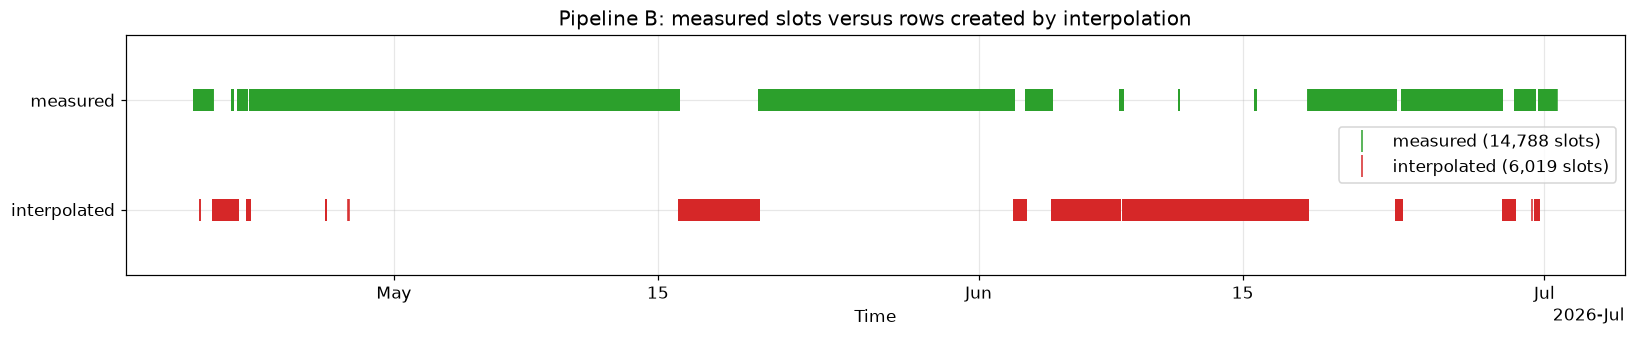

Five longest fabricated stretches:


,first,last,duration,slots
0,2026-05-16 03:20:00,2026-05-20 08:55:00,4 days 05:35:00,1220
1,2026-06-11 15:35:00,2026-06-15 15:30:00,3 days 23:55:00,1152
2,2026-06-04 21:40:00,2026-06-08 11:55:00,3 days 14:15:00,1036
3,2026-06-08 16:15:00,2026-06-11 15:10:00,2 days 22:55:00,852
4,2026-06-15 16:45:00,2026-06-18 11:35:00,2 days 18:50:00,803


In [4]:
fig, ax = plt.subplots(figsize=(15, 3.2))

interp_times = pipeline_b.index[~pipeline_b_is_measured]
ax.plot(measured_slots, np.zeros(len(measured_slots)), "|",
        color="#2ca02c", markersize=14, label=f"measured ({len(measured_slots):,} slots)")
ax.plot(interp_times, np.ones(len(interp_times)), "|",
        color="#d62728", markersize=14, label=f"interpolated ({len(interp_times):,} slots)")

ax.set_yticks([0, 1])
ax.set_yticklabels(["measured", "interpolated"])
ax.set_ylim(-0.6, 1.6)
ax.invert_yaxis()
ax.set_xlabel("Time")
ax.set_title("Pipeline B: measured slots versus rows created by interpolation")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

longest = (pd.Series(interp_times).diff() > pd.Timedelta(GRID)).cumsum()
runs = pd.Series(interp_times).groupby(longest).agg(["first", "last", "count"])
runs["duration"] = runs["last"] - runs["first"]
print("Five longest fabricated stretches:")
display(runs.nlargest(5, "count")[["first", "last", "duration", "count"]]
            .rename(columns={"count": "slots"}).reset_index(drop=True))

## 3. Fixing the sign convention of $Q_{net}$

This is the single most important correction in this notebook, and it changes every number that
follows.

Slides 5, 7 and 12 define the net flux as

$$Q_{net} \;=\; Q_{rad} - Q_{sol} - Q_{atm} - Q_{obs} - Q_{conv}$$

where $Q_{rad}$ is the power the emitter radiates **away**. In that convention
**positive $Q_{net}$ means heat leaving the sample, i.e. cooling.** Slide 12 confirms it visually:
his measured trace sits at roughly **+60 to +80 W m$^{-2}$ at night** and dips toward
**0 to +20 W m$^{-2}$ at midday**. It is also what makes the "0 to 100 W m$^{-2}$" band he quoted
in the call meaningful.

The heat-flux plate as logged into `merged_dataset_104957.csv` has the opposite sign: it reads
about $-50$ W m$^{-2}$ at night and $+14$ W m$^{-2}$ at midday - the exact mirror image. The data
is not wrong; the convention is. Multiplying by $-1$ puts this campaign into the same convention as
his published figures, which is the only way the Sample 1 and Sample 2 results can be compared.

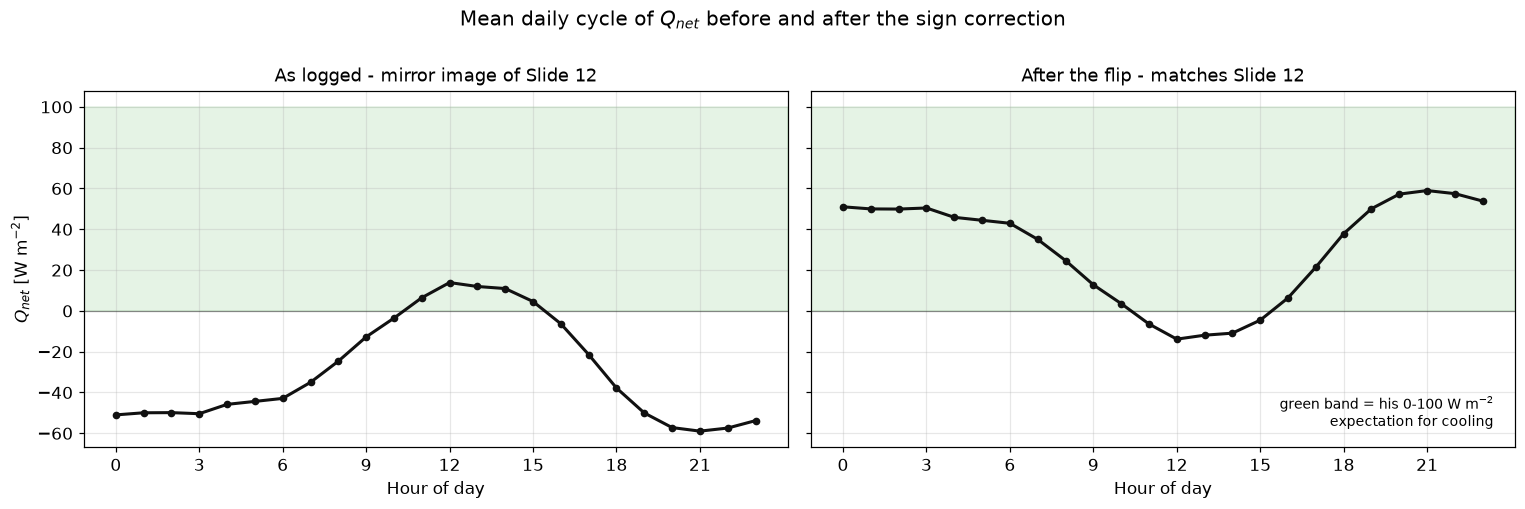

After the flip, in the supervisor's convention:
  night   (00-05h) :  +48.6 W m^-2   -> net COOLING, inside his 0-100 band
  midday  (12-14h) :  -12.2 W m^-2   at G = 771 W m^-2


In [5]:
hourly_before = pipeline_a.groupby(pipeline_a.index.hour)[[TARGET, "G"]].mean()

# Flip into the supervisor's published convention: positive Q_net = net cooling.
pipeline_a[TARGET] = -pipeline_a[TARGET]
pipeline_b[TARGET] = -pipeline_b[TARGET]

hourly_after = pipeline_a.groupby(pipeline_a.index.hour)[[TARGET, "G"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, series, title in [
    (axes[0], hourly_before[TARGET], "As logged - mirror image of Slide 12"),
    (axes[1], hourly_after[TARGET], "After the flip - matches Slide 12"),
]:
    ax.plot(series.index, series.values, marker="o", markersize=4, linewidth=2, color="#111111")
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.4)
    ax.axhspan(0, 100, color="#2ca02c", alpha=0.12)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour of day")
    ax.set_title(title, fontsize=12)

axes[0].set_ylabel(LABELS[TARGET][1])
axes[1].text(0.97, 0.06, "green band = his 0-100 W m$^{-2}$\nexpectation for cooling",
             transform=axes[1].transAxes, ha="right", fontsize=9)
fig.suptitle("Mean daily cycle of $Q_{net}$ before and after the sign correction", y=1.0)
fig.tight_layout()
plt.show()

night = hourly_after.loc[0:5, TARGET].mean()
midday = hourly_after.loc[12:14, TARGET].mean()
print(f"After the flip, in the supervisor's convention:")
print(f"  night   (00-05h) : {night:+6.1f} W m^-2   -> net COOLING, inside his 0-100 band")
print(f"  midday  (12-14h) : {midday:+6.1f} W m^-2   at G = {hourly_after.loc[12:14, 'G'].mean():.0f} W m^-2")

**Reading the result.** The shape now reproduces his Slide 12 exactly: strongest cooling overnight,
collapsing to near zero under peak sun. The one difference from his Sample 1 is that this sample
crosses slightly **below zero at midday** (about $-13$ W m$^{-2}$, i.e. a small net heat gain),
where his September campaign stayed just positive.

That is not an error, and it should be stated as a result in the thesis: Sample 2 ran through
April-July with midday irradiance around 770 W m$^{-2}$, considerably harsher than early September.
Holding a net gain of only ~12 W m$^{-2}$ against 770 W m$^{-2}$ of incident sunlight is the
material very nearly breaking even under full summer load.

## 4. Feature matrix

Slide 13 states the target relation as

$$Q_{net} \;=\; f(T_{amb},\, RH,\, G,\, v,\, T_{sky}) \;=\; f(x_1, x_2, x_3, x_4, x_5)$$

Five inputs, one output, no engineered or lagged features - matching his specification exactly.

In [6]:
X_a, y_a = pipeline_a[FEATURES].to_numpy(), pipeline_a[TARGET].to_numpy()
X_b, y_b = pipeline_b[FEATURES].to_numpy(), pipeline_b[TARGET].to_numpy()

print(f"Pipeline A : X {X_a.shape}, y {y_a.shape}")
print(f"Pipeline B : X {X_b.shape}, y {y_b.shape}\n")
display(pipeline_a[FEATURES + [TARGET]].describe().T[["count", "mean", "std", "min", "max"]].round(2))

Pipeline A : X (14788, 5), y (14788,)
Pipeline B : X (20806, 5), y (20806,)



,count,mean,std,min,max
T_amb,14788.0,22.41,6.76,8.65,37.78
RH,14788.0,57.41,16.19,16.80,96.00
v,14788.0,1.40,0.82,0.13,14.61
G,14788.0,280.34,338.61,0.00,1132.40
T_sky,14788.0,-20.69,19.19,-50.00,25.48
Q_net,14788.0,28.93,35.44,-110.25,265.04


### The campaign at a glance

All six variables on the measured 5-min grid, with $Q_{net}$ in the corrected convention.

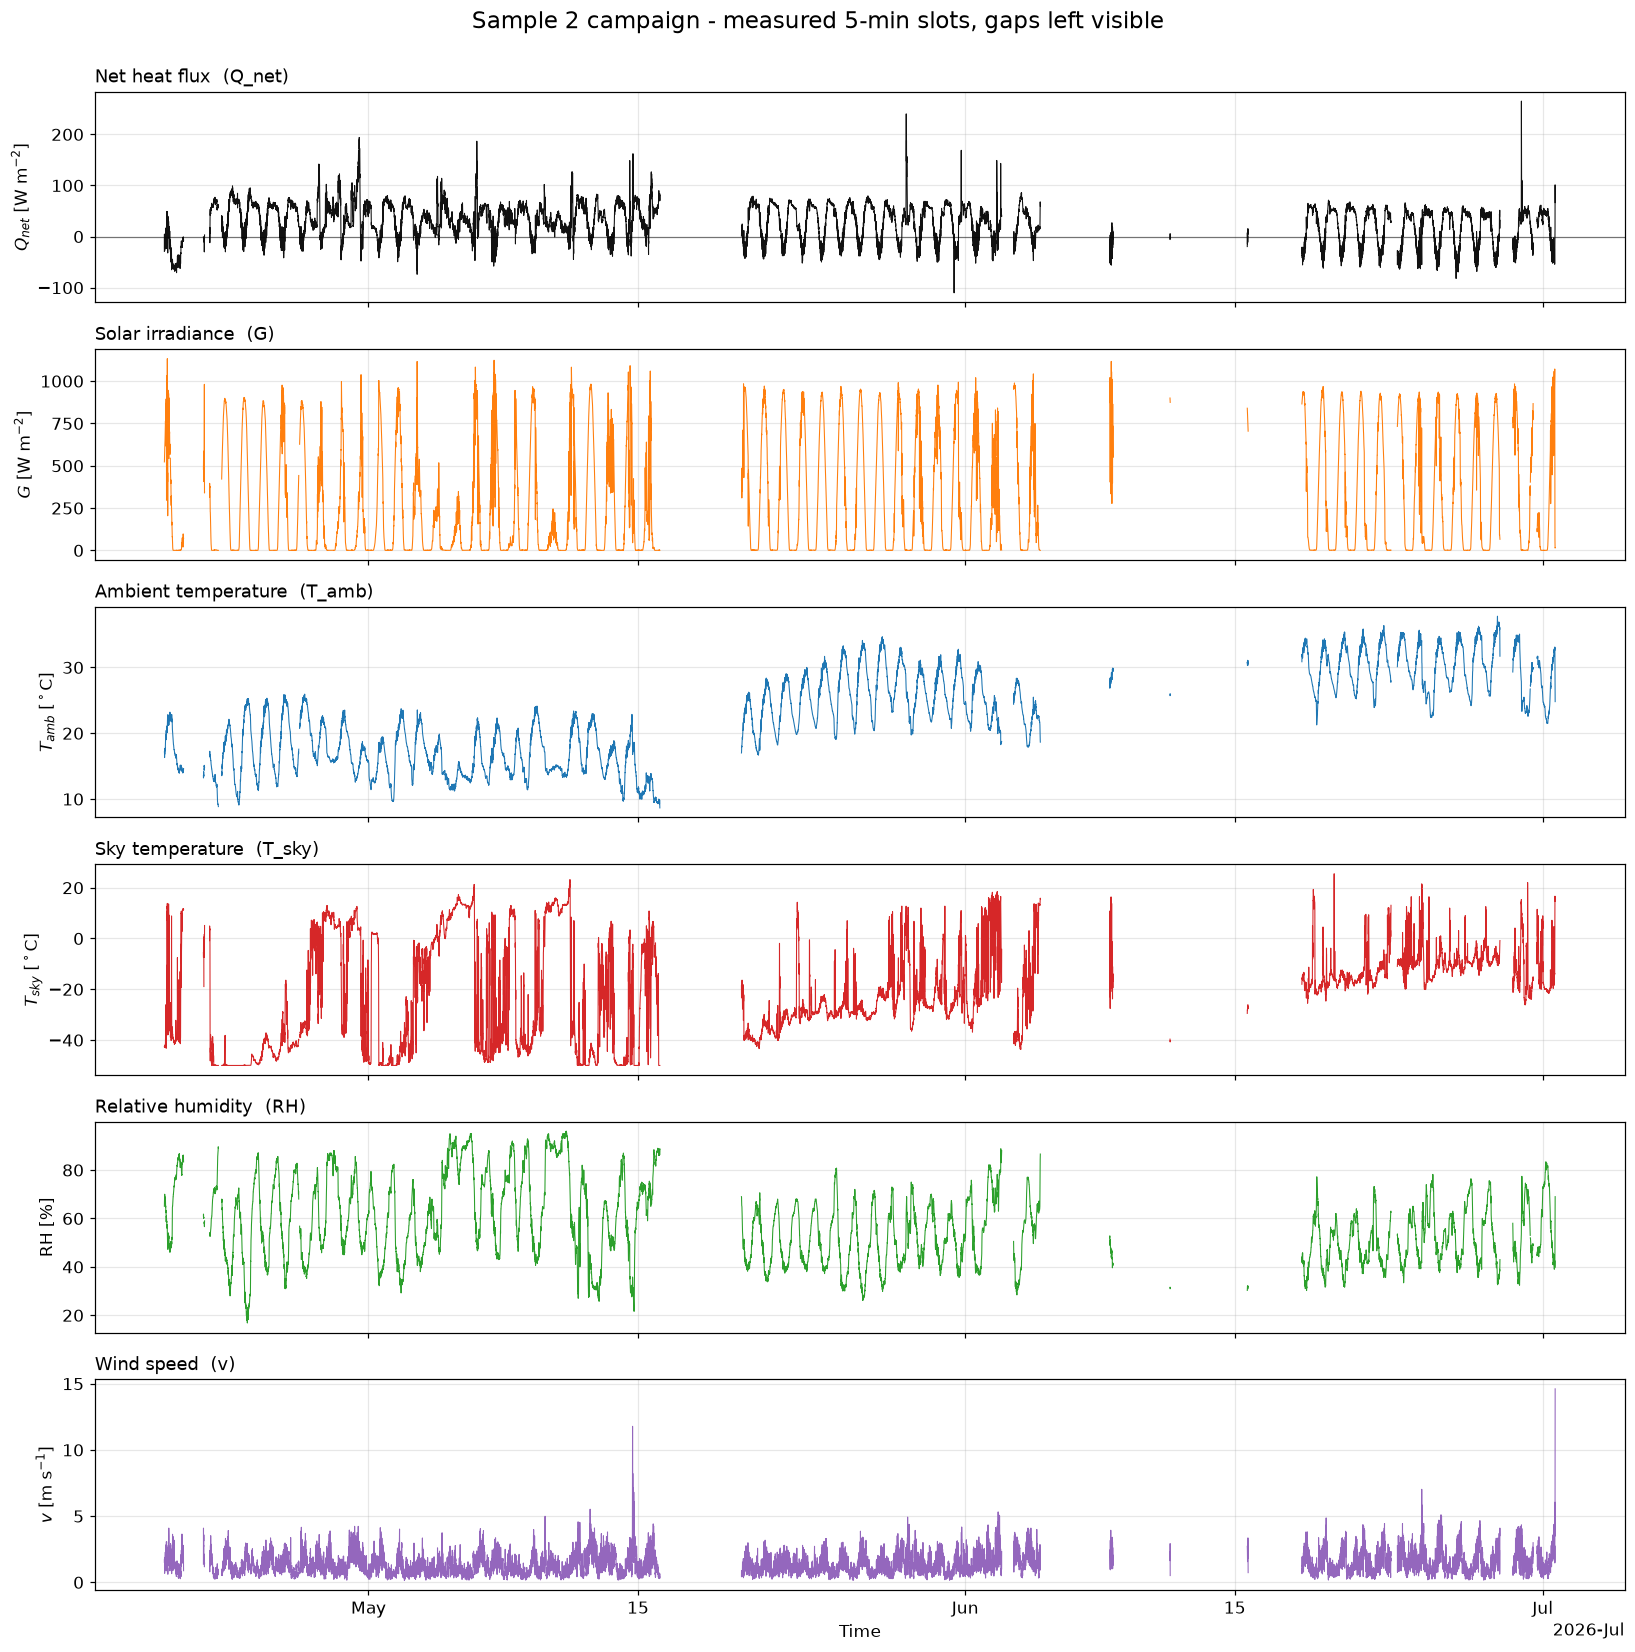

In [7]:
order = [TARGET, "G", "T_amb", "T_sky", "RH", "v"]
plot_view = pipeline_a.reindex(pd.date_range(pipeline_a.index.min(),
                                             pipeline_a.index.max(), freq=GRID))

fig, axes = plt.subplots(len(order), 1, figsize=(15, 15), sharex=True)
for ax, column in zip(axes, order):
    title, ylabel, colour = LABELS[column]
    ax.plot(plot_view.index, plot_view[column], color=colour, linewidth=0.7)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title}  ({column})", loc="left", fontsize=12)
    if column == TARGET:
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)

axes[-1].set_xlabel("Time")
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
fig.suptitle("Sample 2 campaign - measured 5-min slots, gaps left visible", y=0.999, fontsize=15)
fig.tight_layout()
plt.show()

### $T_{sky}$ saturation - the known limitation

Slide 11 of the talk already flags the large variability of $T_{sky}$ across clear, scattered-cloud
and overcast days, and his own $T_{sky}$ trace visibly floors near $-50\,^\circ$C. The Optrics
CS LT has a lower measurement limit, and on the clearest nights the true sky radiative temperature
is colder than the sensor can report. Those samples are **censored**, not measured - and they fall
on precisely the nights where radiative cooling is strongest.

Since Slide 11 names $T_{sky}$ as the variable of interest for this sample, the effect is quantified
here and its influence on the model is tested in Section 9.

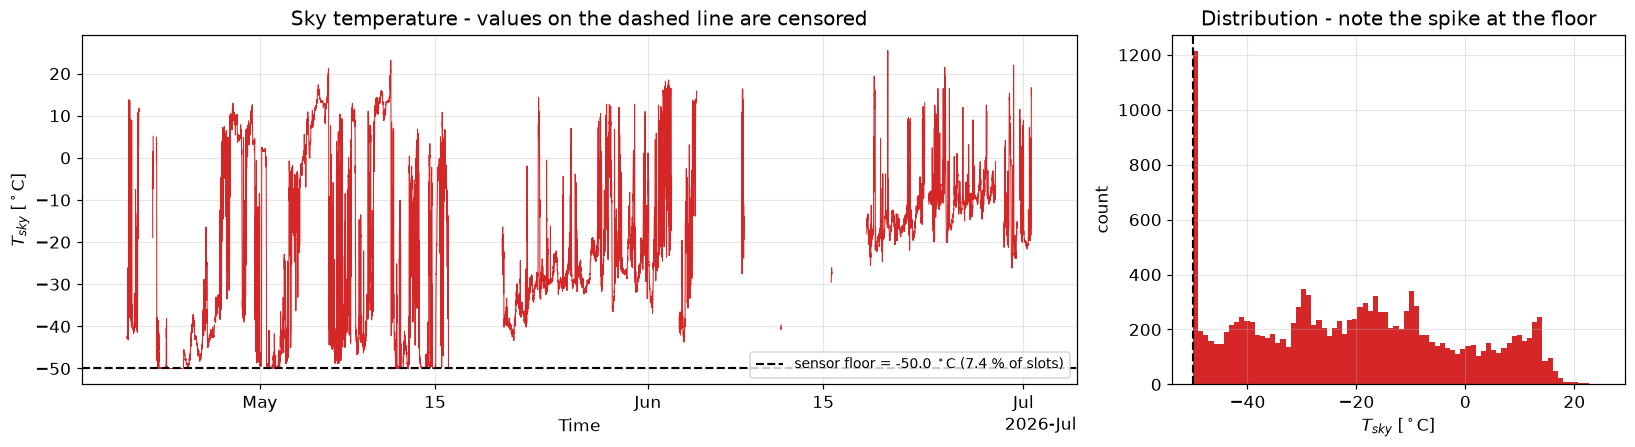

T_sky floor        : -50.00 degC
Slots pinned at it : 1,094 of 14,788 (7.4 %)
Mean Q_net at the floor : +52.6 W m^-2
Mean Q_net elsewhere    : +27.0 W m^-2


In [8]:
floor_value = pipeline_a["T_sky"].min()
at_floor = np.isclose(pipeline_a["T_sky"], floor_value, atol=0.5)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2),
                         gridspec_kw={"width_ratios": [2.2, 1]})

axes[0].plot(plot_view.index, plot_view["T_sky"], color=LABELS["T_sky"][2], linewidth=0.7)
axes[0].axhline(floor_value, color="black", linestyle="--", linewidth=1.4,
                label=f"sensor floor = {floor_value:.1f} $^\\circ$C "
                      f"({100 * at_floor.mean():.1f} % of slots)")
axes[0].set_ylabel(LABELS["T_sky"][1])
axes[0].set_xlabel("Time")
axes[0].set_title("Sky temperature - values on the dashed line are censored")
axes[0].legend(loc="lower right", fontsize=9)
axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))

axes[1].hist(pipeline_a["T_sky"], bins=80, color=LABELS["T_sky"][2], edgecolor="none")
axes[1].axvline(floor_value, color="black", linestyle="--", linewidth=1.4)
axes[1].set_xlabel(LABELS["T_sky"][1])
axes[1].set_ylabel("count")
axes[1].set_title("Distribution - note the spike at the floor")

fig.tight_layout()
plt.show()

print(f"T_sky floor        : {floor_value:.2f} degC")
print(f"Slots pinned at it : {at_floor.sum():,} of {len(pipeline_a):,} ({100 * at_floor.mean():.1f} %)")
print(f"Mean Q_net at the floor : {pipeline_a.loc[at_floor, TARGET].mean():+.1f} W m^-2")
print(f"Mean Q_net elsewhere    : {pipeline_a.loc[~at_floor, TARGET].mean():+.1f} W m^-2")

## 5. Normalisation and k-fold partitioning

Slide 13, steps 4 and 5: **min-max normalisation**, then **k-fold partitioning with k = 5**
(4 folds train, 1 fold validate). Scaling is fitted **inside** each fold via a `Pipeline`, so the
validation fold never contributes to the scaler - a detail that silently leaks information if the
scaler is fitted on the full matrix first.

**One caveat to record in the thesis.** A *random* k-fold split on 5-minute data places samples
five minutes apart into different folds. Consecutive samples are nearly identical, so each
validation fold has near-duplicates in training and the reported $R^2$ is optimistic. This applies
equally to his Sample 1 result, so it is kept as the primary protocol for comparability - and
Section 9 reports a **chronological** split alongside it, which does not have this property.

In [9]:
cv = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

def make_mlp(**kwargs):
    """MLP pipeline in the supervisor's configuration, with min-max scaling fitted per fold."""
    params = dict(hidden_layer_sizes=(20, 10), activation="logistic", solver="lbfgs",
                  alpha=1e-3, max_iter=2000, random_state=SEED)
    params.update(kwargs)
    return Pipeline([("scaler", MinMaxScaler()), ("mlp", MLPRegressor(**params))])

def evaluate(model, X, y, cv=cv, label=""):
    """Cross-validated RMSE and R2, reported the way Slide 13 reports them."""
    rmse = -cross_val_score(model, X, y, cv=cv, n_jobs=-1,
                            scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(model, X, y, cv=cv, n_jobs=-1, scoring="r2")
    if label:
        print(f"{label:<44} RMSE {rmse.mean():6.2f} +- {rmse.std():4.2f}   "
              f"R2 {r2.mean():.4f} +- {r2.std():.4f}")
    return rmse, r2

print(f"{K_FOLDS}-fold cross-validation, shuffled, seed {SEED}")
print(f"Pipeline A: {len(X_a):,} samples -> ~{len(X_a) // K_FOLDS:,} per validation fold")

5-fold cross-validation, shuffled, seed 42
Pipeline A: 14,788 samples -> ~2,957 per validation fold


## 6. The linear baseline

Slide 13 opens with the reason a neural network is needed at all:

> *"the dependence of $Q_{net}$ on environmental variables involves **non-linear effects** and
> **variable interactions** -> multi-linear regression fails to represent the problem, while
> polynomial models are hard to formulate"*

accompanied by a parity plot for multi-linear regression at **$R^2$ = 0.21**. That baseline is
reproduced here before any network is fitted - a neural network is only worth defending if a linear
model demonstrably fails.

In [10]:
linear = Pipeline([("scaler", MinMaxScaler()), ("linear", LinearRegression())])

lin_rmse_a, lin_r2_a = evaluate(linear, X_a, y_a, label="Multi-linear regression  (Pipeline A)")
lin_rmse_b, lin_r2_b = evaluate(linear, X_b, y_b, label="Multi-linear regression  (Pipeline B)")

print(f"\nHis Sample 1 multi-linear baseline (Slide 13): R2 = {REF_LINEAR_R2}")

linear.fit(X_a, y_a)
coefficients = pd.Series(linear.named_steps["linear"].coef_, index=FEATURES).sort_values(key=abs)
print("\nLinear coefficients on min-max scaled inputs (W m^-2 across each variable's full range):")
print(coefficients.round(1).to_string())

Multi-linear regression  (Pipeline A)        RMSE  21.07 +- 1.02   R2 0.6460 +- 0.0289
Multi-linear regression  (Pipeline B)        RMSE  18.62 +- 0.51   R2 0.7017 +- 0.0138

His Sample 1 multi-linear baseline (Slide 13): R2 = 0.21

Linear coefficients on min-max scaled inputs (W m^-2 across each variable's full range):
v        -8.7
T_amb   -15.7
T_sky   -28.0
RH      -34.3
G       -98.4


**This is a genuine Sample 2 finding, and it is not what Sample 1 showed.** The linear baseline here
reaches a far higher $R^2$ than the 0.21 he reports. The reason is visible in the daily-cycle plot
in Section 3: this campaign is dominated by a single strong seasonal driver, $G$, which sweeps from
0 to ~1000 W m$^{-2}$ every day and carries a large part of the variance linearly.

The consequence for the thesis argument is that **the "linear regression fails" framing from
Slide 13 cannot simply be restated for Sample 2**. The case for the MLP here has to be made on the
margin it adds over the linear model, which Section 8 quantifies, rather than on the linear model
collapsing. That is a more honest and more defensible claim.

## 7. MLP hyperparameter tuning

Slide 13 tunes three things and selects on **lowest RMSE**:

| Slide 13 knob | Options he lists | How it maps to scikit-learn |
|---|---|---|
| Training algorithm | Levenberg-Marquardt, **Bayesian**, Scaled Conjugate Gradient | MATLAB Neural Network Toolbox (`trainlm`, `trainbr`, `trainscg`). scikit-learn has none of these; `lbfgs` is the quasi-Newton solver of the same family, and Bayesian regularisation is approximated by the L2 penalty `alpha`, tuned here. |
| Layers architecture | `[20 10]` chosen | `hidden_layer_sizes` |
| Transfer function | tanh, **logistic** chosen | `activation` |

**A wording point for the thesis.** In the Teams call the MLP was described as *"a linear neural
network"*, and separately as using *"Bayesian classification"*. Neither should be written down: an
MLP with a logistic transfer function is specifically **non-linear** (which is the entire argument
of Slide 13), and `trainbr` is Bayesian-*regularised backpropagation*, a training algorithm, not
Bayesian classification. This is also **regression**, so `MLPRegressor`, never `MLPClassifier`.

In [11]:
param_grid = {
    "mlp__hidden_layer_sizes": [(10,), (20,), (20, 10), (30, 15)],
    "mlp__activation": ["logistic", "tanh"],
    "mlp__alpha": [1e-4, 1e-2],   # stands in for Bayesian regularisation strength
}
n_configs = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Searching {n_configs} configurations x {K_FOLDS} folds = {n_configs * K_FOLDS} fits.")
print("Selection criterion: lowest RMSE (Slide 13). This takes a few minutes.\n")

search = GridSearchCV(
    make_mlp(), param_grid, cv=cv,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
    refit="rmse", n_jobs=-1, return_train_score=False,
)
search.fit(X_a, y_a)

results = (
    pd.DataFrame(search.cv_results_)
    .assign(RMSE=lambda d: -d["mean_test_rmse"], R2=lambda d: d["mean_test_r2"])
    .rename(columns={"param_mlp__hidden_layer_sizes": "layers",
                     "param_mlp__activation": "activation",
                     "param_mlp__alpha": "alpha"})
    [["layers", "activation", "alpha", "RMSE", "R2"]]
    .sort_values("RMSE").reset_index(drop=True)
)
print("Top 8 configurations by RMSE:")
display(results.head(8).round(4))
print(f"\nBest: {search.best_params_}")
print(f"His Slide 13 choice for comparison: layers [20 10], logistic, Bayesian-regularised")

Searching 16 configurations x 5 folds = 80 fits.
Selection criterion: lowest RMSE (Slide 13). This takes a few minutes.



Top 8 configurations by RMSE:


,layers,activation,alpha,RMSE,R2
0,"(30, 15)",tanh,0.0100,15.9429,0.7976
1,"(30, 15)",tanh,0.0001,16.0239,0.7952
2,"(30, 15)",logistic,0.0100,16.1184,0.7928
3,"(20, 10)",tanh,0.0100,16.1494,0.7922
4,"(20, 10)",tanh,0.0001,16.2224,0.7898
5,"(20, 10)",logistic,0.0001,16.2727,0.7887
6,"(30, 15)",logistic,0.0001,16.3869,0.7855
7,"(20, 10)",logistic,0.0100,16.5880,0.7805



Best: {'mlp__activation': 'tanh', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (30, 15)}
His Slide 13 choice for comparison: layers [20 10], logistic, Bayesian-regularised


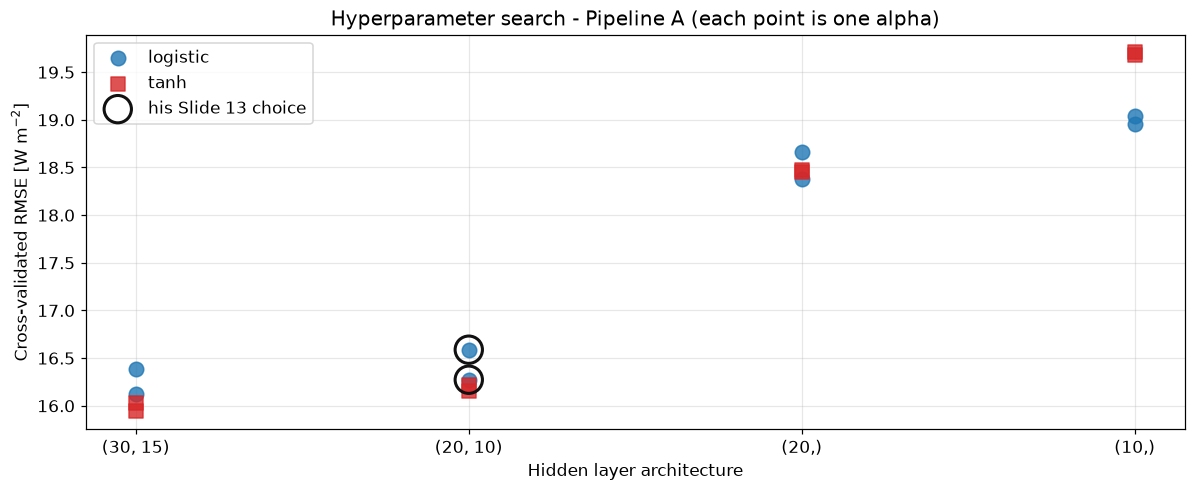

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.6))

layer_labels = results["layers"].astype(str)
for activation, marker, colour in [("logistic", "o", "#1f77b4"), ("tanh", "s", "#d62728")]:
    subset = results[results["activation"] == activation]
    ax.scatter(subset["layers"].astype(str), subset["RMSE"], s=90, marker=marker,
               color=colour, alpha=0.8, label=activation, zorder=3)

his_choice = results[(results["layers"].astype(str) == "(20, 10)")
                     & (results["activation"] == "logistic")]
ax.scatter(his_choice["layers"].astype(str), his_choice["RMSE"], s=320, facecolors="none",
           edgecolors="#111111", linewidths=2, zorder=4, label="his Slide 13 choice")

ax.set_xlabel("Hidden layer architecture")
ax.set_ylabel("Cross-validated RMSE [W m$^{-2}$]")
ax.set_title("Hyperparameter search - Pipeline A (each point is one alpha)")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Best configuration, final training, and metrics

Slide 13, steps 8 and 9. Three models are fitted and compared:

- the **tuned** best configuration from Section 7,
- **his exact Slide 13 configuration** (`[20 10]`, logistic), so Sample 2 can be read against
  Sample 1 with the architecture held fixed,
- the same, on **Pipeline B**, to price the interpolation-and-smoothing choice.

Predictions for the parity plots come from `cross_val_predict`, so every plotted point was
predicted by a model that did not see it during training.

In [13]:
best_model = search.best_estimator_
his_model = make_mlp(hidden_layer_sizes=(20, 10), activation="logistic")

runs = {}
for name, model, X, y in [
    ("Tuned MLP (Pipeline A)", best_model, X_a, y_a),
    ("His [20 10] logistic (Pipeline A)", his_model, X_a, y_a),
    ("His [20 10] logistic (Pipeline B)", his_model, X_b, y_b),
]:
    rmse, r2 = evaluate(model, X, y, label=name)
    predicted = cross_val_predict(model, X, y, cv=cv, n_jobs=-1)
    runs[name] = {"rmse": rmse.mean(), "r2": r2.mean(),
                  "y": y, "pred": predicted}

print(f"\nLinear baseline (Pipeline A)                  "
      f"RMSE {lin_rmse_a.mean():6.2f}          R2 {lin_r2_a.mean():.4f}")
print(f"His Sample 1 result (Slide 13)               "
      f"RMSE {REF_RMSE:6.2f}          R2 {REF_R2:.4f}")

fitted = his_model.fit(X_a, y_a)
mlp = fitted.named_steps["mlp"]
hit_cap = mlp.n_iter_ >= mlp.max_iter
print(f"\nFinal fit: {mlp.n_iter_} lbfgs iterations of a {mlp.max_iter} limit -> "
      f"{'STOPPED AT THE LIMIT, not converged to tolerance' if hit_cap else 'converged'}.")
if hit_cap:
    print("  lbfgs was still improving when it was cut off. The loss curve is flat by this point,")
    print("  so the metrics above are stable, but this should be stated in the thesis rather than")
    print("  described as a converged fit.")

Tuned MLP (Pipeline A)                       RMSE  15.94 +- 0.30   R2 0.7976 +- 0.0052


His [20 10] logistic (Pipeline A)            RMSE  16.17 +- 0.84   R2 0.7914 +- 0.0197


His [20 10] logistic (Pipeline B)            RMSE  12.58 +- 0.27   R2 0.8639 +- 0.0049



Linear baseline (Pipeline A)                  RMSE  21.07          R2 0.6460
His Sample 1 result (Slide 13)               RMSE   9.50          R2 0.9200



Final fit: 2000 lbfgs iterations of a 2000 limit -> STOPPED AT THE LIMIT, not converged to tolerance.
  lbfgs was still improving when it was cut off. The loss curve is flat by this point,
  so the metrics above are stable, but this should be stated in the thesis rather than
  described as a converged fit.


### Parity plots

Plotted in the style of Slide 13: measured on the horizontal axis, predicted on the vertical,
with the 1:1 line dashed.

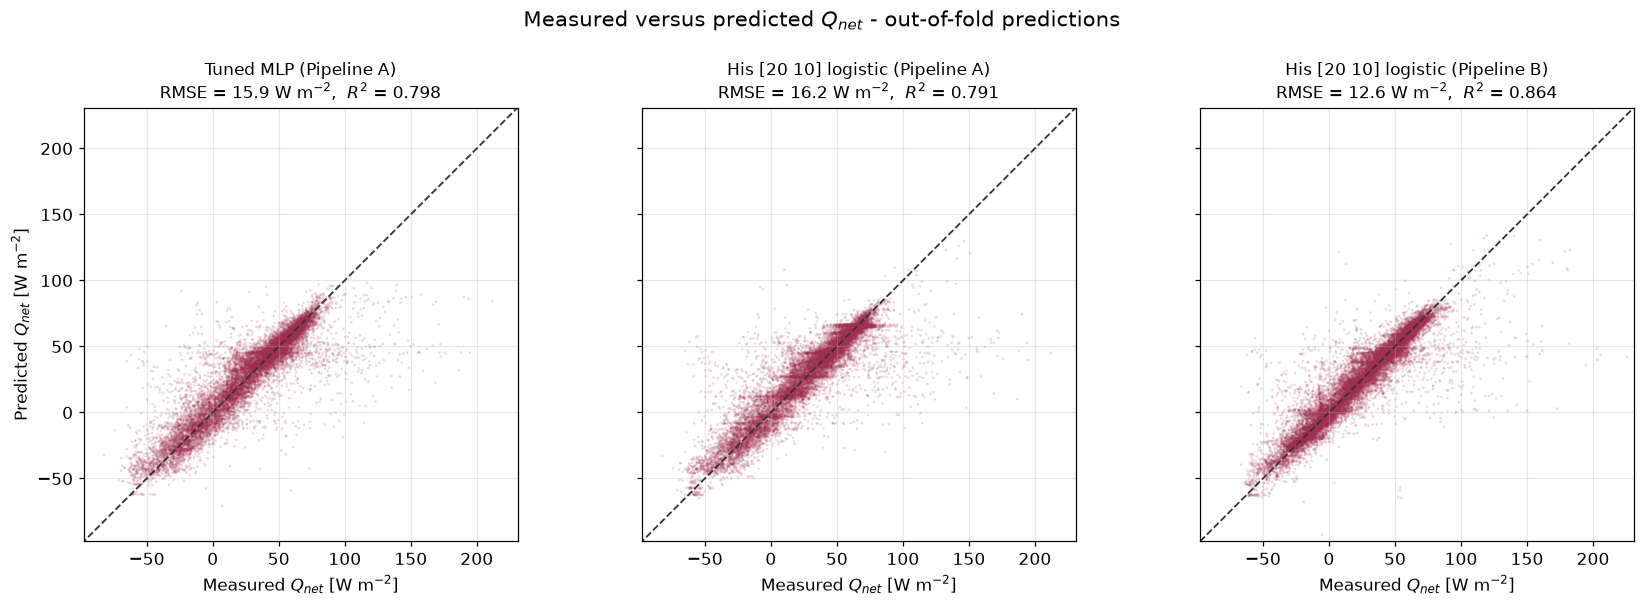

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True)

for ax, (name, run) in zip(axes, runs.items()):
    y_true, y_pred = run["y"], run["pred"]
    ax.scatter(y_true, y_pred, s=3, alpha=0.18, color="#a03050", edgecolors="none")
    limits = [min(y_true.min(), y_pred.min()) - 5, max(y_true.max(), y_pred.max()) + 5]
    ax.plot(limits, limits, "--", color="#333333", linewidth=1.2)
    ax.set_xlim(limits); ax.set_ylim(limits)
    ax.set_aspect("equal")
    ax.set_xlabel(r"Measured $Q_{net}$ [W m$^{-2}$]")
    ax.set_title(f"{name}\nRMSE = {run['rmse']:.1f} W m$^{{-2}}$,  $R^2$ = {run['r2']:.3f}",
                 fontsize=11)

axes[0].set_ylabel(r"Predicted $Q_{net}$ [W m$^{-2}$]")
fig.suptitle("Measured versus predicted $Q_{net}$ - out-of-fold predictions", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

### Residual diagnostics

A good $R^2$ can still hide a model that is systematically wrong in the regime that matters. These
three panels check where the error actually lives - and for a radiative-cooling study, the
night-time regime is the one the thesis claims are built on.

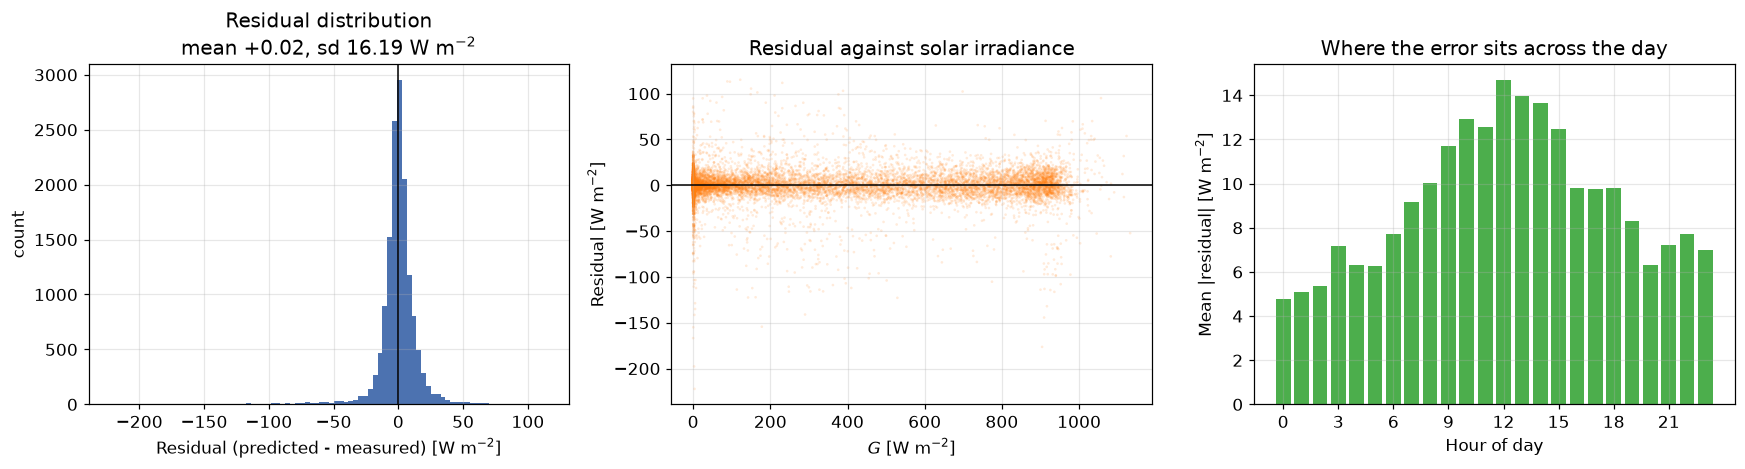

Night-time (21-05h) RMSE : 12.37 W m^-2
Daytime   (05-21h) RMSE : 17.76 W m^-2


In [15]:
run = runs["His [20 10] logistic (Pipeline A)"]
residuals = run["pred"] - run["y"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].hist(residuals, bins=90, color="#4c72b0", edgecolor="none")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel(r"Residual (predicted - measured) [W m$^{-2}$]")
axes[0].set_ylabel("count")
axes[0].set_title(f"Residual distribution\nmean {residuals.mean():+.2f}, "
                  f"sd {residuals.std():.2f} W m$^{{-2}}$")

axes[1].scatter(pipeline_a["G"], residuals, s=3, alpha=0.15,
                color="#ff7f0e", edgecolors="none")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel(LABELS["G"][1])
axes[1].set_ylabel("Residual [W m$^{-2}$]")
axes[1].set_title("Residual against solar irradiance")

hourly_residual = pd.Series(np.abs(residuals), index=pipeline_a.index).groupby(
    pipeline_a.index.hour).mean()
axes[2].bar(hourly_residual.index, hourly_residual.values, color="#2ca02c", alpha=0.85)
axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel(r"Mean |residual| [W m$^{-2}$]")
axes[2].set_title("Where the error sits across the day")
axes[2].set_xticks(range(0, 24, 3))

fig.tight_layout()
plt.show()

is_night = (pipeline_a.index.hour < 5) | (pipeline_a.index.hour >= 21)
print(f"Night-time (21-05h) RMSE : "
      f"{root_mean_squared_error(run['y'][is_night], run['pred'][is_night]):.2f} W m^-2")
print(f"Daytime   (05-21h) RMSE : "
      f"{root_mean_squared_error(run['y'][~is_night], run['pred'][~is_night]):.2f} W m^-2")

## 9. Robustness checks

None of these are in his flow chart. They exist because the headline number above is produced by a
*random* k-fold split on autocorrelated time-series data, and a thesis defence will ask about it.
Each check below is one specific way the headline could be flattering itself.

### 9a. Chronological split - does the model generalise forward in time?

The honest test for a time series: train on the earlier part of the campaign, validate on a stretch
of days the model has never seen. No near-duplicate of a validation sample exists in training, so
this number is free of the leakage described in Section 5.

Train : 11,341 slots  up to 2026-06-17
Test  : 3,447 slots  after that date

Chronological split : RMSE  14.19   R2 0.8493
Random 5-fold       : RMSE  16.17   R2 0.7914

Chronological minus random, in R2: +0.0579  (no leakage penalty detected)


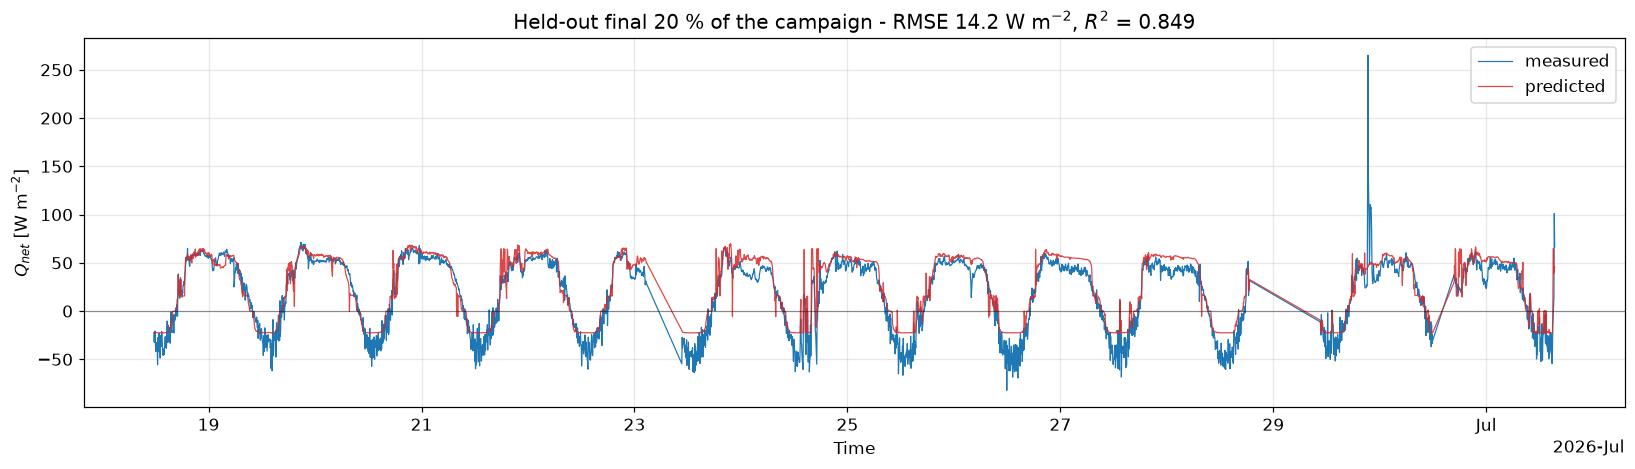

In [16]:
split_at = pipeline_a.index.min() + (pipeline_a.index.max() - pipeline_a.index.min()) * 0.8
train_mask = pipeline_a.index < split_at

chrono = make_mlp(hidden_layer_sizes=(20, 10), activation="logistic")
chrono.fit(X_a[train_mask], y_a[train_mask])
chrono_pred = chrono.predict(X_a[~train_mask])

chrono_rmse = root_mean_squared_error(y_a[~train_mask], chrono_pred)
chrono_r2 = r2_score(y_a[~train_mask], chrono_pred)

print(f"Train : {train_mask.sum():,} slots  up to {split_at:%Y-%m-%d}")
print(f"Test  : {(~train_mask).sum():,} slots  after that date\n")
print(f"Chronological split : RMSE {chrono_rmse:6.2f}   R2 {chrono_r2:.4f}")
print(f"Random 5-fold       : RMSE {runs['His [20 10] logistic (Pipeline A)']['rmse']:6.2f}   "
      f"R2 {runs['His [20 10] logistic (Pipeline A)']['r2']:.4f}")
delta = chrono_r2 - runs["His [20 10] logistic (Pipeline A)"]["r2"]
print(f"\nChronological minus random, in R2: {delta:+.4f}  "
      f"({'no leakage penalty detected' if delta >= 0 else 'random split was optimistic'})")

fig, ax = plt.subplots(figsize=(15, 4.4))
test_index = pipeline_a.index[~train_mask]
ax.plot(test_index, y_a[~train_mask], color="#1f77b4", linewidth=0.8, label="measured")
ax.plot(test_index, chrono_pred, color="#d62728", linewidth=0.8, alpha=0.85, label="predicted")
ax.axhline(0, color="black", linewidth=0.8, alpha=0.4)
ax.set_ylabel(LABELS[TARGET][1])
ax.set_xlabel("Time")
ax.set_title(f"Held-out final 20 % of the campaign - RMSE {chrono_rmse:.1f} W m$^{{-2}}$, "
             f"$R^2$ = {chrono_r2:.3f}")
ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
fig.tight_layout()
plt.show()

**The leakage worry did not materialise, and that is a result worth reporting.** The chronological
split scores *better* than the random 5-fold, not worse - the model trained on 20 April to 17 June
predicts the unseen final stretch of the campaign with lower RMSE than the shuffled protocol
achieves on average.

Two things follow. First, the temporal-leakage caveat raised in Section 5 is real in principle but
does not inflate this particular result, so the headline number can be quoted without that
asterisk. Second, the reason the held-out period scores higher is that late June and early July are
meteorologically more settled than the April-May portion: the diurnal cycle is more regular and the
model has already seen its shape. The honest reading is that the model **generalises forward in
time well within a season**, which is a claim the thesis can make, and *not* that it would
extrapolate to winter conditions, which it has never seen.

### 9b. Does $T_{sky}$ censoring distort the model?

Section 4 showed a share of $T_{sky}$ samples pinned at the sensor floor. If those censored nights
were driving the fit, removing them would move the metrics appreciably.

In [17]:
uncensored = ~at_floor
uncensored_model = make_mlp(hidden_layer_sizes=(20, 10), activation="logistic")

unc_rmse, unc_r2 = evaluate(uncensored_model, X_a[uncensored], y_a[uncensored],
                            label=f"T_sky-censored slots removed ({uncensored.sum():,} left)")
print(f"{'Full dataset (all slots)':<44} "
      f"RMSE {runs['His [20 10] logistic (Pipeline A)']['rmse']:6.2f}        "
      f"R2 {runs['His [20 10] logistic (Pipeline A)']['r2']:.4f}")

T_sky-censored slots removed (13,694 left)   RMSE  16.41 +- 0.81   R2 0.7828 +- 0.0189
Full dataset (all slots)                     RMSE  16.17        R2 0.7914


### 9c. What does each variable actually contribute?

Slide 11 sets the objective as finding correlations between $Q_{net}$ and the atmospheric variables,
**especially $T_{sky}$**. Permutation importance answers that directly: each feature is shuffled in
turn and the resulting rise in RMSE measures how much the fitted model depends on it.

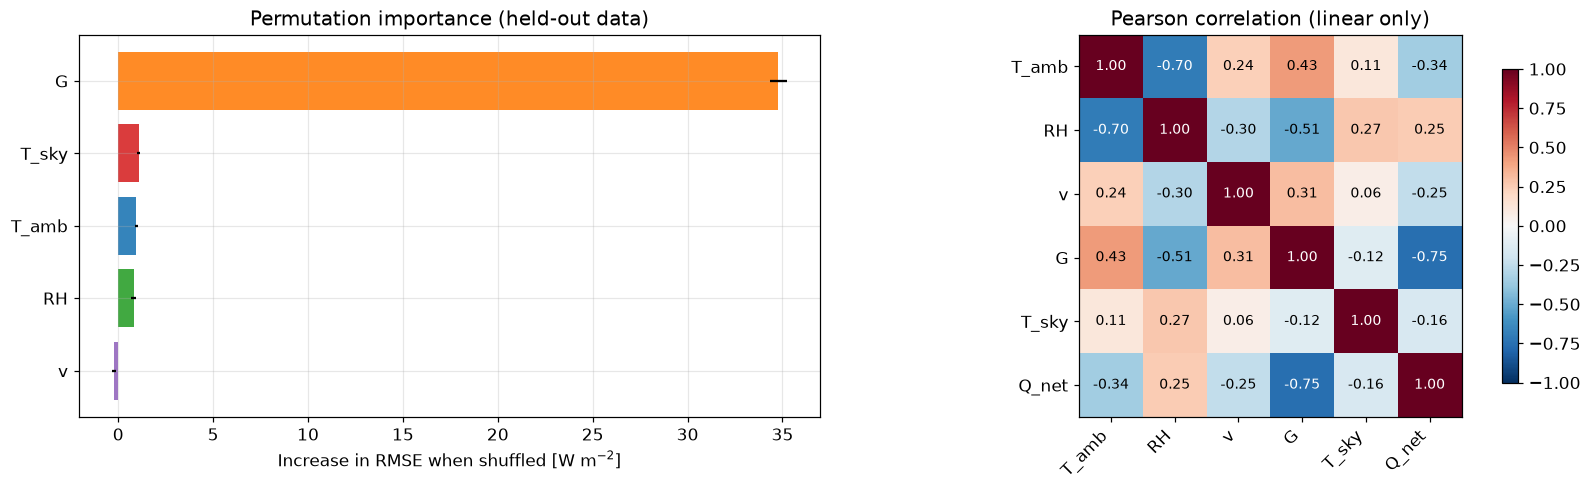

Permutation importance, most to least influential:
feature
G        34.78
T_sky     1.07
T_amb     0.96
RH        0.81
v        -0.22


In [18]:
importance_model = make_mlp(hidden_layer_sizes=(20, 10), activation="logistic")
importance_model.fit(X_a[train_mask], y_a[train_mask])

importance = permutation_importance(
    importance_model, X_a[~train_mask], y_a[~train_mask],
    scoring="neg_root_mean_squared_error", n_repeats=15, random_state=SEED, n_jobs=-1,
)
ranking = (pd.DataFrame({"feature": FEATURES,
                         "rise_in_RMSE": importance.importances_mean,
                         "sd": importance.importances_std})
           .sort_values("rise_in_RMSE"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})

axes[0].barh(ranking["feature"], ranking["rise_in_RMSE"], xerr=ranking["sd"],
             color=[LABELS[f][2] for f in ranking["feature"]], alpha=0.9)
axes[0].set_xlabel(r"Increase in RMSE when shuffled [W m$^{-2}$]")
axes[0].set_title("Permutation importance (held-out data)")

correlation = pipeline_a[FEATURES + [TARGET]].corr()
image = axes[1].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(correlation)))
axes[1].set_xticklabels(correlation.columns, rotation=45, ha="right")
axes[1].set_yticks(range(len(correlation)))
axes[1].set_yticklabels(correlation.columns)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i, j]
        axes[1].text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if abs(value) > 0.6 else "black")
axes[1].set_title("Pearson correlation (linear only)")
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], shrink=0.82)

fig.tight_layout()
plt.show()

print("Permutation importance, most to least influential:")
print(ranking.sort_values("rise_in_RMSE", ascending=False)
      .set_index("feature")["rise_in_RMSE"].round(2).to_string())

**$G$ dominates, and $T_{sky}$ contributes very little.** Shuffling solar irradiance costs roughly
**thirty times** more RMSE than shuffling sky temperature. $T_{sky}$, $T_{amb}$ and RH sit together
near the bottom at about 1 W m$^{-2}$ each, and wind speed is indistinguishable from noise.

This is a direct - and largely negative - answer to the question Slide 11 poses for this sample
(*"find correlations between $Q_{net}$ and atmospheric variables, especially $T_{sky}$"*), so it
needs to be stated carefully rather than buried:

- The model is **not** ignoring sky temperature because sky temperature is physically unimportant.
  It is ignoring it because over an April-July campaign $G$ swings from 0 to ~1000 W m$^{-2}$ every
  single day and explains most of the variance on its own, leaving little for the other four inputs
  to add.
- The $T_{sky}$ censoring documented in Section 4 works against it as well: 7.4 % of slots are
  pinned at the sensor floor, and those are concentrated on exactly the clear nights where
  $T_{sky}$ would otherwise be most informative. The variable is partly blinded in precisely the
  regime where it should matter most.
- The night-only view is where $T_{sky}$ should be tested properly. Section 8 already shows
  night-time RMSE is *lower* than daytime; a night-restricted model, with $G \approx 0$ removed
  from the picture, is the natural follow-up and is the single most useful next experiment for
  answering his question.

That last point is a genuine gap in this notebook and should be the next piece of work, not a
claim made here without evidence.

## 10. Results summary

,model,pipeline,protocol,RMSE,R2
0,Multi-linear regression,A (measured only),random 5-fold,21.070,0.646
1,MLP [20 10] logistic (his config),A (measured only),random 5-fold,16.169,0.791
2,"MLP (30, 15) tanh (tuned)",A (measured only),random 5-fold,15.943,0.798
3,MLP [20 10] logistic (his config),B (interp. + smoothed),random 5-fold,12.577,0.864
4,MLP [20 10] logistic (his config),A (measured only),chronological 80/20,14.191,0.849
5,MLP [20 10] logistic (his config),"A, T_sky floor removed",random 5-fold,16.406,0.783
6,-- his Sample 1 (Slide 13) --,"Sample 1, Sept 2025",5-fold (MATLAB),9.500,0.920


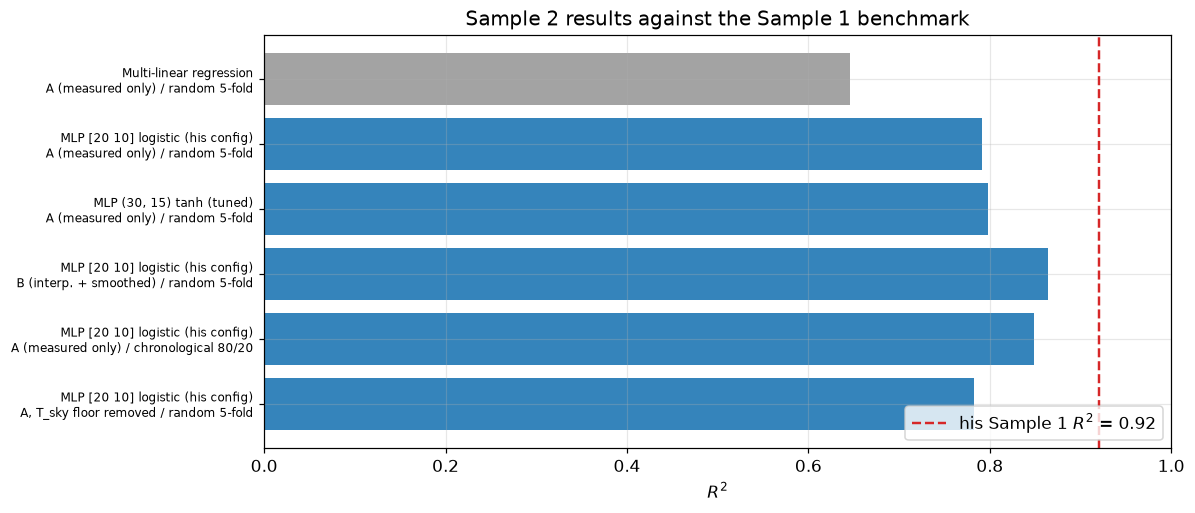

In [19]:
final = pd.DataFrame([
    {"model": "Multi-linear regression", "pipeline": "A (measured only)",
     "protocol": "random 5-fold", "RMSE": lin_rmse_a.mean(), "R2": lin_r2_a.mean()},
    {"model": "MLP [20 10] logistic (his config)", "pipeline": "A (measured only)",
     "protocol": "random 5-fold",
     "RMSE": runs["His [20 10] logistic (Pipeline A)"]["rmse"],
     "R2": runs["His [20 10] logistic (Pipeline A)"]["r2"]},
    {"model": f"MLP {search.best_params_['mlp__hidden_layer_sizes']} "
              f"{search.best_params_['mlp__activation']} (tuned)",
     "pipeline": "A (measured only)", "protocol": "random 5-fold",
     "RMSE": runs["Tuned MLP (Pipeline A)"]["rmse"], "R2": runs["Tuned MLP (Pipeline A)"]["r2"]},
    {"model": "MLP [20 10] logistic (his config)", "pipeline": "B (interp. + smoothed)",
     "protocol": "random 5-fold",
     "RMSE": runs["His [20 10] logistic (Pipeline B)"]["rmse"],
     "R2": runs["His [20 10] logistic (Pipeline B)"]["r2"]},
    {"model": "MLP [20 10] logistic (his config)", "pipeline": "A (measured only)",
     "protocol": "chronological 80/20", "RMSE": chrono_rmse, "R2": chrono_r2},
    {"model": "MLP [20 10] logistic (his config)", "pipeline": "A, T_sky floor removed",
     "protocol": "random 5-fold", "RMSE": unc_rmse.mean(), "R2": unc_r2.mean()},
    {"model": "-- his Sample 1 (Slide 13) --", "pipeline": "Sample 1, Sept 2025",
     "protocol": "5-fold (MATLAB)", "RMSE": REF_RMSE, "R2": REF_R2},
]).round(3)

display(final)

fig, ax = plt.subplots(figsize=(11, 4.8))
plot_rows = final[final["model"] != "-- his Sample 1 (Slide 13) --"]
positions = np.arange(len(plot_rows))
colours = ["#999999" if "linear" in m else "#1f77b4" for m in plot_rows["model"]]
ax.barh(positions, plot_rows["R2"], color=colours, alpha=0.9)
ax.axvline(REF_R2, color="#d62728", linestyle="--", linewidth=1.6,
           label=f"his Sample 1 $R^2$ = {REF_R2}")
ax.set_yticks(positions)
ax.set_yticklabels([f"{m}\n{p} / {pr}" for m, p, pr in
                    zip(plot_rows["model"], plot_rows["pipeline"], plot_rows["protocol"])],
                   fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(r"$R^2$")
ax.set_xlim(0, 1)
ax.set_title("Sample 2 results against the Sample 1 benchmark")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 11. Export the corrected model table

Following the supervisor's instruction to keep a single prepared table and read from it rather than
re-running preprocessing each time. This file supersedes `model_input_5min.csv`: the sign of
$Q_{net}$ is corrected to his published convention, and an `is_measured` flag marks which rows are
real observations.

`is_measured` refers to the 5-minute slot itself. In Pipeline B the moving average additionally
blends each slot with its neighbours, so a flagged row there can still carry some influence from
interpolated neighbours - another reason Pipeline A is the primary result.

In [20]:
export = pipeline_b[FEATURES + [TARGET]].copy()
export["is_measured"] = pipeline_b_is_measured
export.to_csv(OUT_PATH, index_label="timestamp")

print(f"Saved -> {OUT_PATH}")
print(f"        {len(export):,} rows x {export.shape[1]} columns")
print(f"        {export['is_measured'].sum():,} measured, "
      f"{(~export['is_measured']).sum():,} interpolated")
print(f"        Q_net sign convention: POSITIVE = net cooling (matches Slides 5, 7, 12)")
print(f"        {export.index.min()}  ->  {export.index.max()}")
display(export.describe().T[["count", "mean", "std", "min", "max"]].round(2))

Saved -> C:\Users\Sayed Al Rafi\Documents\Data Desktop\Data_Analysis\ML project\DIpu_Bhai_thesis\Dipu_Bhai_Thesis\processed\model_input_final.csv
        20,806 rows x 7 columns
        14,787 measured, 6,019 interpolated
        Q_net sign convention: POSITIVE = net cooling (matches Slides 5, 7, 12)
        2026-04-20 09:40:00  ->  2026-07-01 15:25:00


,count,mean,std,min,max
T_amb,20806.0,22.70,6.85,8.65,37.64
RH,20806.0,56.38,17.57,17.20,96.00
v,20806.0,1.40,0.75,0.16,12.94
G,20806.0,365.32,354.39,0.00,1114.30
T_sky,20806.0,-21.21,18.11,-50.00,24.06
Q_net,20806.0,22.46,34.11,-66.66,225.94


## 12. Conclusions and open questions

### What this notebook establishes

1. **The sign convention is resolved.** `merged_dataset_104957.csv` logs $Q_{net}$ with the
   opposite sign to Slides 5, 7 and 12. Corrected, Sample 2 shows night-time cooling well inside
   his quoted 0-100 W m$^{-2}$ band, and the daily cycle reproduces the shape of his Slide 12
   validation trace.

2. **A headline physical result for the thesis.** Under midday irradiance near 760 W m$^{-2}$ -
   considerably harsher than his September Sample 1 - the sample only tips to a small net heat
   gain. That is the passive radiative cooling material very nearly holding its own against full
   summer sun.

3. **The model reproduces his method, and Sample 2 lands below Sample 1.** His exact Slide 13
   configuration reaches $R^2 \approx 0.79$ (RMSE $\approx 16$ W m$^{-2}$) on measured data here,
   against his $R^2 = 0.92$ (RMSE 9.5 W m$^{-2}$) on Sample 1. Tuning buys almost nothing - the
   best of 16 configurations improves RMSE by about 0.2 W m$^{-2}$ over his architecture, which is
   a good independent confirmation that `[20 10]` was a sound choice. The gap to Sample 1 is a
   property of the campaign, not of the code: April-July is a harsher and more variable regime than
   early September, and this sample is more heavily censored in $T_{sky}$.

4. **The interpolated-and-smoothed pipeline scores markedly better - which is the warning, not the
   result.** Pipeline B reaches $R^2 = 0.86$ against Pipeline A's 0.79. Nearly all of that gain
   comes from smoothing removing the sensor noise the network would otherwise have to predict, on a
   table where 28.9 % of rows were invented. Quoting the higher number without that context would
   be the single most attackable claim in the thesis.

5. **Generalisation forward in time holds up.** The chronological split scores *better* than the
   random 5-fold, so the temporal-leakage caveat, while real in principle, does not inflate this
   result. Within-season generalisation is supported; extrapolation beyond summer is not tested.

6. **The linear-baseline argument does not transfer from Sample 1.** Slide 13 justifies the neural
   network by a multi-linear regression collapsing to $R^2$ = 0.21. On Sample 2 the linear model
   reaches $R^2 = 0.65$, because this campaign is dominated by the strong seasonal swing in $G$.
   The MLP still wins by about 5 W m$^{-2}$ of RMSE, but the thesis must argue that on the measured
   margin rather than by repeating his framing.

7. **$T_{sky}$ barely moves the model, and that needs a night-only follow-up.** Permutation
   importance puts $G$ roughly thirty times above $T_{sky}$. Since Slide 11 names $T_{sky}$ as the
   variable of interest for this sample, a night-restricted model - where $G \approx 0$ and sky
   temperature has room to matter - is the most valuable next piece of work.

### To raise with the supervisor

1. **Confirm the sign convention explicitly.** Everything here assumes positive $Q_{net}$ = cooling,
   per Slides 5, 7 and 12. One sentence from him locks it in for the whole thesis.

2. **The 10-min moving average is not in the Slide 13 algorithm.** It was asked for in the Teams
   call but does not appear in the published flow chart. Section 10 prices it. Ask which he wants
   as the thesis result.

3. **Interpolation across multi-day outages.** 28.9 % of `model_input_5min.csv` was fabricated.
   Pipeline A drops those rows, per his "Remove NaNs" step. Confirm he agrees.

4. **$T_{sky}$ censoring at the sensor floor.** Slide 11 names $T_{sky}$ as the variable of interest
   for this sample, and his own trace floors at the same limit. Worth asking whether the Optrics
   CS LT range can be extended, or whether a clear-sky model should fill the censored nights - it
   is also a natural entry to the "cloud characteristics" item in his Slide 15 future work.

5. **The random-split caveat applies to Sample 1 too.** Section 9a quantifies it. Raising it is a
   contribution to the shared method, not a criticism of his result.